In [2]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display

# Cargar el archivo de audio
audio_file = "audio_muestra.mp3"
y, sr = librosa.load(audio_file, sr=None)

In [6]:
print('sr ',sr)
print('y ',y.shape)

Duración del audio:  181.25496598639455 segundos


In [7]:
print("Duración del audio: ", librosa.get_duration(y=y, sr=sr), "segundos")

Muestras:  [ 9.7285717e-09 -3.3764763e-08  1.9175202e-08 ...  3.5841950e-07
  1.2120952e-06  6.7495296e-07]


In [7]:
from pydub import AudioSegment
y_norm = np.interp(y, (y.min(), y.max()), (-1, +1))

# Convertir las muestras de audio a int16
samples = (np.iinfo(np.int16).max * y_norm).astype(np.int16)

audio=AudioSegment(
    samples.tobytes(),
    frame_rate=sr,
    sample_width=samples.dtype.itemsize,
    channels=1
)
audio.export("reconstruyendo_audio.mp3", format="mp3")

<_io.BufferedRandom name='reconstruyendo_audio.mp3'>

[[  94   94   94 ...   94   94   94]
 [  94   94   94 ...   94   94   94]
 [  94   94   94 ... -147 -147 -146]
 ...
 [  94   94   94 ...   94   94   94]
 [  94   94   94 ...   94   94   94]
 [  94   94   94 ...   94   94   94]]
32767
-32767
normalized_matrix [[128 128 128 ... 128 128 128]
 [128 128 128 ... 128 128 128]
 [128 128 128 ... 127 127 127]
 ...
 [128 128 128 ... 128 128 128]
 [128 128 128 ... 128 128 128]
 [128 128 128 ... 128 128 128]]


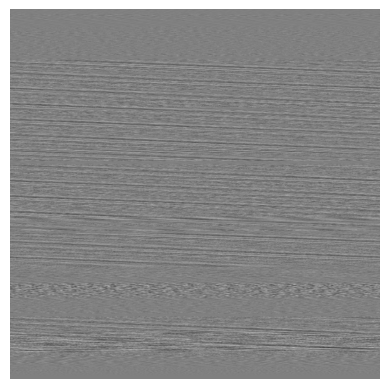

In [58]:
import numpy as np
from PIL import Image

import matplotlib.pyplot as plt
# Determine the dimensions of the matrix
num_samples = len(samples)
width = int(np.sqrt(num_samples))
height = num_samples // width
num_samples_fit = width * height

# Reshape the samples array into a rectangular matrix
matrix = np.reshape(samples[:(width*height)], (height, width))
matrix=matrix.astype(np.int32)
# Print the matrix
print(matrix)
print(np.max(matrix))
print(np.min(matrix))
max_value = np.max(matrix)
min_value = np.min(matrix)

normalized_matrix = (matrix - min_value) / (max_value - min_value) * 255
normalized_matrix = np.round(normalized_matrix).astype(np.uint8)
print("normalized_matrix", normalized_matrix)
# Convert samples to grayscale image
plt.imshow(matrix, cmap='gray')
plt.axis('off')
plt.show()
# Convert the matrix to a grayscale image
image = Image.fromarray(normalized_matrix)

# Save the image as a JPG file
image.save('grayscale_image.jpg')

In [55]:
print(matrix)
print(np.max(matrix))
print(np.min(matrix))
print(abs(np.min(matrix)))
normalized_matrix=matrix + abs(np.min(matrix))
print(normalized_matrix)
print(np.max(normalized_matrix))
print(np.min(normalized_matrix))

[[  94   94   94 ...   94   94   94]
 [  94   94   94 ...   94   94   94]
 [  94   94   94 ... -147 -147 -146]
 ...
 [  94   94   94 ...   94   94   94]
 [  94   94   94 ...   94   94   94]
 [  94   94   94 ...   94   94   94]]
32767
-32767
32767
[[32861 32861 32861 ... 32861 32861 32861]
 [32861 32861 32861 ... 32861 32861 32861]
 [32861 32861 32861 ... 32620 32620 32621]
 ...
 [32861 32861 32861 ... 32861 32861 32861]
 [32861 32861 32861 ... 32861 32861 32861]
 [32861 32861 32861 ... 32861 32861 32861]]
65534
0


In [36]:
print(np.min(matrix))
print(matrix-np.min(matrix))
print(matrix)

-32767
[[-32675 -32675 -32675 ... -32675 -32675 -32675]
 [-32675 -32675 -32675 ... -32675 -32675 -32675]
 [-32675 -32675 -32675 ...  32620  32620  32621]
 ...
 [-32675 -32675 -32675 ... -32675 -32675 -32675]
 [-32675 -32675 -32675 ... -32675 -32675 -32675]
 [-32675 -32675 -32675 ... -32675 -32675 -32675]]
[[  94   94   94 ...   94   94   94]
 [  94   94   94 ...   94   94   94]
 [  94   94   94 ... -147 -147 -146]
 ...
 [  94   94   94 ...   94   94   94]
 [  94   94   94 ...   94   94   94]
 [  94   94   94 ...   94   94   94]]


In [60]:
from PIL import Image
import numpy as np

# Read the image
image = Image.open("grayscale_image.jpg")

# Convert the image to grayscale

# Convert the image to a numpy array
matrix = np.array(image)
print(matrix)
# Normalize the values to range from 0 to 1
matrix_normalized =( matrix / 255.0)*(max_value - min_value) + min_value

# Print the normalized matrix
print(matrix_normalized)


[[128 128 128 ... 128 128 128]
 [128 128 128 ... 127 127 127]
 [129 129 129 ... 129 129 129]
 ...
 [128 128 128 ... 128 128 128]
 [128 128 128 ... 128 128 128]
 [128 128 128 ... 128 128 128]]
[[ 128.49803922  128.49803922  128.49803922 ...  128.49803922
   128.49803922  128.49803922]
 [ 128.49803922  128.49803922  128.49803922 ... -128.49803922
  -128.49803922 -128.49803922]
 [ 385.49411765  385.49411765  385.49411765 ...  385.49411765
   385.49411765  385.49411765]
 ...
 [ 128.49803922  128.49803922  128.49803922 ...  128.49803922
   128.49803922  128.49803922]
 [ 128.49803922  128.49803922  128.49803922 ...  128.49803922
   128.49803922  128.49803922]
 [ 128.49803922  128.49803922  128.49803922 ...  128.49803922
   128.49803922  128.49803922]]


In [61]:
print(np.max(matrix_normalized))

32767.0


In [64]:
from pydub import AudioSegment

# y_norm = np.interp(y, (y.min(), y.max()), (-1, +1))

# Convertir las muestras de audio a int16
matrix_flattened = matrix_normalized.flatten()
samples = (np.iinfo(np.int16).max * matrix_normalized).astype(np.int16)

audio = AudioSegment(
    samples.tobytes(),
    frame_rate=44100,
    sample_width=samples.dtype.itemsize,
    channels=1,
)
audio.export("reconstruyendo_audio_img.mp3", format="mp3")

<_io.BufferedRandom name='reconstruyendo_audio_img.mp3'>